# Predictive Maintenance Model Training (LightGBM)
In this notebook, we load the dataset created in `eda_and_features.ipynb`, split it chronologically into training and test sets, train a multiclass **LightGBM** model to predict component failures 24 hours in advance, and evaluate its results.

In [ ]:
# Libraries for data handling, LightGBM modelling, evaluation metrics and plotting
import pandas as pd
import sqlite3
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [77]:
# Load the engineered dataset
connection = sqlite3.connect('../data/maintenance.db')
data = pd.read_csv('../data/features.csv')
data['datetime'] = pd.to_datetime(data['datetime'])

## 1. Temporal Train / Test Split
Because we are working with time series and 24-hour rolling windows, splitting rows randomly would leak future information into the training set. Instead, we split the data by date:
- **Training set:** January to September 2015 (first 9 months).
- **Test set:** October to December 2015 (last 3 months).

In [ ]:
# Cut-off date: October 1st, 2015
cut = pd.to_datetime('2015-10-01 00:00:00')

# Convert machine model to category so LightGBM can use it directly
data['model'] = data['model'].astype('category')

df_train = data[data['datetime'] < cut]
df_test = data[data['datetime'] >= cut]

# Separate input features (X) and target variable (y), dropping ID and timestamp columns
X_train = df_train.drop(columns=['failure_next_24h', 'datetime', 'machineID'])
y_train = df_train['failure_next_24h']
X_test = df_test.drop(columns=['failure_next_24h', 'datetime', 'machineID'])
y_test = df_test['failure_next_24h']

## 2. Training the Multiclass LightGBM Model
Most of the time (over 98% of the hours), machines run normally (`none`). If we don't account for this imbalance, the model could just predict `'none'` every time. We set `class_weight='balanced'` so the model pays special attention to the four failure classes (`comp1`-`comp4`).

In [ ]:
# Configure and train the LightGBM classifier for 5 classes (comp1-comp4 + none)
model_lgb_multi = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    class_weight='balanced', 
    objective='multiclass',  
    num_class=5,             
    random_state=42,
    n_jobs=-1
)

model_lgb_multi.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.146303 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6160
[LightGBM] [Info] Number of data points in the train set: 654600, number of used features: 31
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438


,objective,'multiclass'
,class_weight,'balanced'
,random_state,42
,n_jobs,-1
,num_class,5
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000


## 3. Evaluating the Model on the Test Set
Now we test our model on the unseen data from October to December. We look at:
1. **Confusion Matrix:** to see how many failures are caught vs. false alarms.
2. **Precision, Recall & F1-Score:** in maintenance, **Recall** is critical (we don't want to miss a real breakdown), while **Precision** tells us how reliable our alerts are.

In [80]:
# Generate predictions on the test set (Oct - Dec)
predictions = model_lgb_multi.predict(X_test)

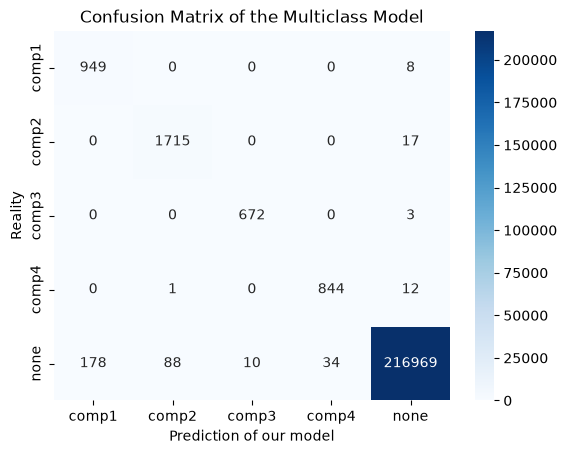

In [ ]:
# Plot and save the Confusion Matrix
class_names = ['comp1', 'comp2', 'comp3', 'comp4', 'none']
cm = confusion_matrix(y_test, predictions)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Reality')
plt.xlabel('Prediction of our model')
plt.title('Confusion Matrix of the Multiclass Model')
plt.tight_layout()
plt.savefig('../img/confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
# Build the classification report table and save it as Markdown for the README
report = classification_report(y_test, predictions, output_dict=True)
metric_table = pd.DataFrame(report).transpose()
print(metric_table.round(2))
with open('../reports/model_metrics.md', 'w', encoding='utf-8') as f:
    f.write(metric_table.round(2).to_markdown())

              precision  recall  f1-score   support
comp1              0.84    0.99      0.91     957.0
comp2              0.95    0.99      0.97    1732.0
comp3              0.99    1.00      0.99     675.0
comp4              0.96    0.98      0.97     857.0
none               1.00    1.00      1.00  217279.0
accuracy           1.00    1.00      1.00       1.0
macro avg          0.95    0.99      0.97  221500.0
weighted avg       1.00    1.00      1.00  221500.0


## 4. Feature Importance: Which Variables Matter Most?
Let's check which features the model used the most to make its decisions. This helps us verify if our 24-hour rolling windows and maintenance counters are actually driving the predictions.

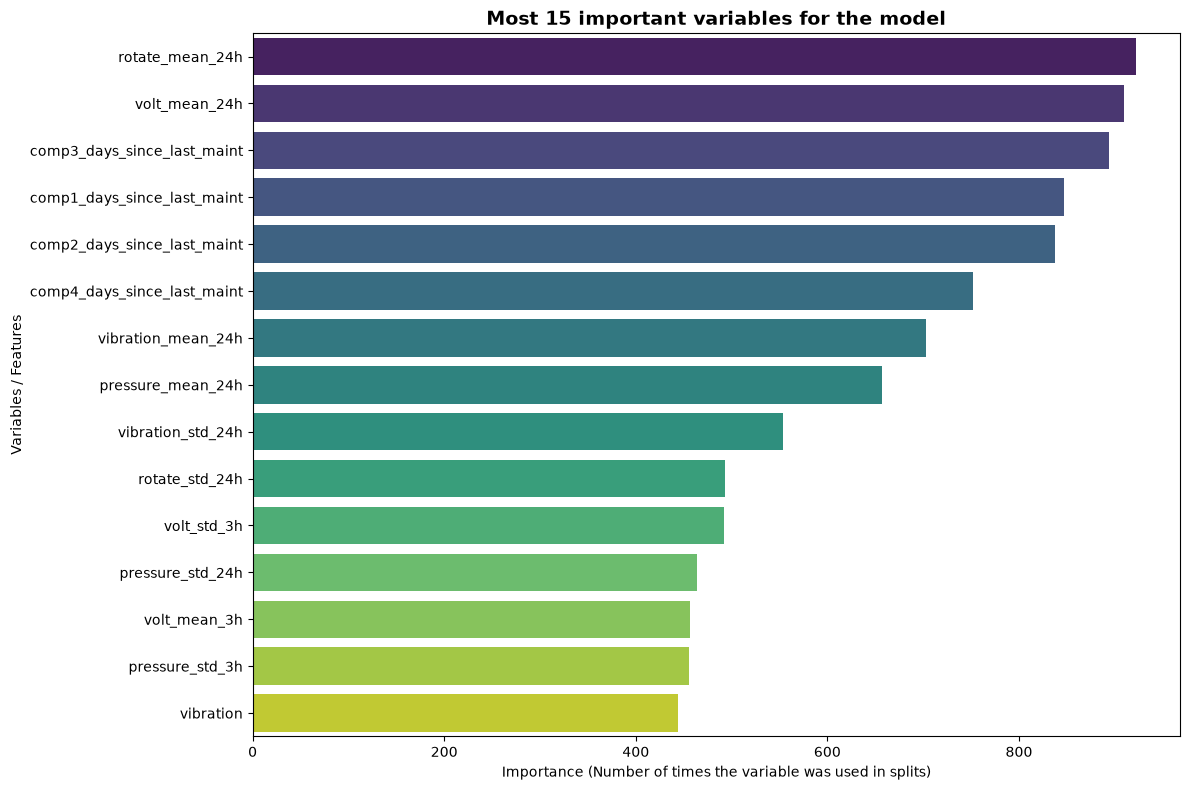

In [ ]:
# Extract and plot the top 15 most important features
importance = pd.DataFrame({
    'Variable': X_train.columns,
    'Importance': model_lgb_multi.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=importance.head(15), x='Importance', y='Variable', hue='Variable', palette='viridis', legend=False)
plt.title('Top 15 Most Important Variables for the Model', fontsize=14, fontweight='bold')
plt.xlabel('Importance (Number of times the variable was used in splits)')
plt.ylabel('Variables / Features')
plt.tight_layout()
plt.savefig('../img/important_variables.png', dpi=300)
plt.show()

## 5. Saving the Trained Model
Finally, we save our trained LightGBM model in `../models/lightgbm_failures.pkl` so we can use it in the next phase of the project.

In [84]:
# Save the trained model to disk
joblib.dump(model_lgb_multi, '../models/lightgbm_failures.pkl')

['../models/lightgbm_failures.pkl']

In [85]:
# Close database connection
connection.close()